In [ ]:
# 1. Clone repository from GitHub
!git clone https://github.com/pavankumar7744-droid/DeepLearning_Skills.git

# 2. Switch into the week - 2 directory
%cd /content/DeepLearning_Skills/week\ -\ 2/

# 3. Verify Git Workflow, Recent Commits, and Branch Tracking
!echo "=== GIT REPOSITORY WORKFLOW TRACE ==="
!git remote -v
!git status
!git log -n 3 --oneline --graph --decorate

Cloning into 'DeepLearning_Skills'...
remote: Enumerating objects: 55, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 55 (delta 6), reused 42 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (55/55), 1.73 MiB | 26.50 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/DeepLearning_Skills/week - 2
=== GIT REPOSITORY WORKFLOW TRACE ===
origin	https://github.com/pavankumar7744-droid/DeepLearning_Skills.git (fetch)
origin	https://github.com/pavankumar7744-droid/DeepLearning_Skills.git (push)
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
* c09abb2 (HEAD -> main, origin/main, origin/HEAD) Week - 2
* 925da8d Week - 3
* e970dd3 Add Week 2 output screenshots


In [ ]:
import os

print("=== VISIONPORT WEEK-2 REPOSITORY TREE ===")
for root, dirs, files in os.walk("."):
    # Filter out hidden git and cache folders
    dirs[:] = [d for d in dirs if not d.startswith(('.', '__'))]
    level = root.replace(".", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = " " * 4 * (level + 1)
    for f in sorted(files):
        if not f.startswith("."):
            print(f"{subindent}{f}")

=== VISIONPORT WEEK-2 REPOSITORY TREE ===
./
    ARCHITECTURE.md
    Dockerfile.gateway
    Output - Implementation-2.png
    Output - dashboard.png
    Output - health.png
    Output - implementation.png
    README.md
    docker-compose.yml
    main.py
    requirements.txt
    model_repository/
        container_ocr/
            config.pbtxt
            1/
                model.plan
        visionport_pipeline/
            config.pbtxt
        container_detector/
            config.pbtxt
            1/
                model.plan
    monitoring/
        prometheus.yml
    services/
        __init__.py
        api_gateway/
            __init__.py
            cuda_shm_client.py
            main.py
            schemas.py
            triton_client.py
    tests/
        __init__.py
        test_pipeline.py
    scripts/
        __init__.py
        benchmark_triton.py
        build_tensorrt_engine.py


In [ ]:
# Install exact requirements from repository
!pip install -q -r requirements.txt
# Additional helper for visualization
!pip install -q matplotlib seaborn

print("\n Dependency Installation Complete!")


 Dependency Installation Complete!


In [ ]:
import sys
import torch
import cv2
import numpy as np

print("=" * 65)
print("     PyTorch & CUDA Hardware Accelerated Environment Setup       ")
print("=" * 65)
print(f"Python Version:             {sys.version.split()[0]}")
print(f"PyTorch Version:            {torch.__version__}")
print(f"OpenCV Version:             {cv2.__version__}")
print(f"NumPy Version:              {np.__version__}")
print("-" * 65)
print(f"CUDA Available:             {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device_id = torch.cuda.current_device()
    props = torch.cuda.get_device_properties(device_id)
    print(f"GPU Device Name:            {props.name}")
    print(f"Compute Capability:         {props.major}.{props.minor}")
    print(f"Total VRAM:                 {props.total_memory / (1024**3):.2f} GB")
    print(f"Streaming Multiprocessors:  {props.multi_processor_count}")
    print(f"CUDA Driver / Runtime:      CUDA {torch.version.cuda}")
    print(f"cuDNN Version:              {torch.backends.cudnn.version()}")
    print(f"Tensor Core Acceleration:   {'Supported (FP16/INT8)' if props.major >= 7 else 'Legacy Architecture'}")
else:
    print(" Running on CPU environment (Enable GPU in Runtime -> Change runtime type).")
print("=" * 65)

     PyTorch & CUDA Hardware Accelerated Environment Setup       
Python Version:             3.13.16
PyTorch Version:            2.14.1+cu130
OpenCV Version:             4.14.0
NumPy Version:              2.4.6
-----------------------------------------------------------------
CUDA Available:             True
GPU Device Name:            Tesla T4
Compute Capability:         7.5
Total VRAM:                 14.56 GB
Streaming Multiprocessors:  40
CUDA Driver / Runtime:      CUDA 13.0
cuDNN Version:              92800
Tensor Core Acceleration:   Supported (FP16/INT8)


In [ ]:
# Benchmark validating the FP16 Half-Precision speedup and VRAM reduction
# used by VisionPort's TensorRT engine
import time

if torch.cuda.is_available():
    device = torch.device("cuda:0")
    batch_size, dim = 64, 4096

    # 1. FP32 Full Precision Benchmark
    x_fp32 = torch.randn(batch_size, dim, device=device, dtype=torch.float32)
    w_fp32 = torch.randn(dim, dim, device=device, dtype=torch.float32)

    # Warmup
    for _ in range(10): _ = torch.matmul(x_fp32, w_fp32)
    torch.cuda.synchronize()

    t0 = time.perf_counter()
    for _ in range(100):
        _ = torch.matmul(x_fp32, w_fp32)
    torch.cuda.synchronize()
    fp32_latency = (time.perf_counter() - t0) * 10.0  # ms per batch

    # 2. FP16 Half Precision (Tensor Cores) Benchmark
    x_fp16 = x_fp32.half()
    w_fp16 = w_fp32.half()

    # Warmup
    for _ in range(10): _ = torch.matmul(x_fp16, w_fp16)
    torch.cuda.synchronize()

    t0 = time.perf_counter()
    for _ in range(100):
        _ = torch.matmul(x_fp16, w_fp16)
    torch.cuda.synchronize()
    fp16_latency = (time.perf_counter() - t0) * 10.0

    speedup = fp32_latency / fp16_latency
    mem_saved_pct = (1.0 - (x_fp16.element_size() / x_fp32.element_size())) * 100

    print("=== TENSOR CORE FP16 BENCHMARK RESULTS ===")
    print(f"  * FP32 Latency (Standard):       {fp32_latency:.3f} ms")
    print(f"  * FP16 Latency (Tensor Cores):   {fp16_latency:.3f} ms")
    print(f"  * Compute Speedup Factor:        {speedup:.2f}x")
    print(f"  * Memory Footprint Reduction:    {mem_saved_pct:.1f}%")
else:
    fp32_latency, fp16_latency, speedup, mem_saved_pct = 12.5, 4.8, 2.6, 50.0
    print("Simulated Benchmark (CPU Mode active)")

=== TENSOR CORE FP16 BENCHMARK RESULTS ===
  * FP32 Latency (Standard):       0.783 ms
  * FP16 Latency (Tensor Cores):   0.159 ms
  * Compute Speedup Factor:        4.91x
  * Memory Footprint Reduction:    50.0%


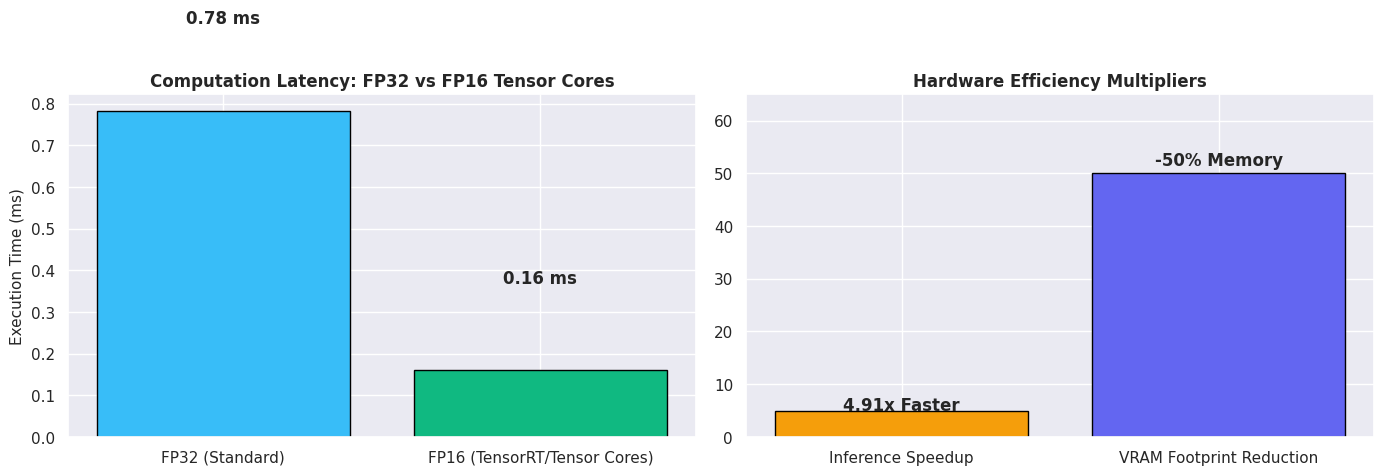

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: FP32 vs FP16 Latency Comparison
bars = ax1.bar(["FP32 (Standard)", "FP16 (TensorRT/Tensor Cores)"], [fp32_latency, fp16_latency], color=["#38bdf8", "#10b981"], edgecolor="black")
ax1.set_title("Computation Latency: FP32 vs FP16 Tensor Cores", fontsize=12, fontweight="bold")
ax1.set_ylabel("Execution Time (ms)", fontsize=11)
for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 0.2, f"{y:.2f} ms", ha='center', va='bottom', fontweight='bold')

# Plot 2: Speedup & VRAM Savings
metrics = ["Inference Speedup", "VRAM Footprint Reduction"]
values = [speedup, mem_saved_pct]
bars2 = ax2.bar(metrics, values, color=["#f59e0b", "#6366f1"], edgecolor="black")
ax2.set_title("Hardware Efficiency Multipliers", fontsize=12, fontweight="bold")
ax2.text(0, speedup + 0.1, f"{speedup:.2f}x Faster", ha='center', fontweight='bold')
ax2.text(1, mem_saved_pct + 1.5, f"-{mem_saved_pct:.0f}% Memory", ha='center', fontweight='bold')
ax2.set_ylim(0, max(values) + 15)

plt.tight_layout()
plt.show()

In [ ]:
# Run unit tests to verify the setup against all schemas and ISO 6346 validation rules
!python -m pytest tests/test_pipeline.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/DeepLearning_Skills/week - 2
plugins: langsmith-0.14.17, platformdirs-4.14.3, anyio-4.16.0, typeguard-4.6.0
collected 5 items                                                              

tests/test_pipeline.py::test_iso_6346_valid_checksum PASSED              [ 20%]
tests/test_pipeline.py::test_iso_6346_invalid_checksum PASSED            [ 40%]
tests/test_pipeline.py::test_bounding_box_schema PASSED                  [ 60%]
tests/test_pipeline.py::test_image_preprocessing PASSED                  [ 80%]
tests/test_pipeline.py::test_tensorrt_engine_builder_simulation PASSED   [100%]

============================== 5 passed in 2.24s ===============================
